# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/notebooks/meeting18_pytorch_mlp_studio.ipynb)

# BME i9400 — Meeting 18
## Studio: A PyTorch MLP on Clinical Tabular Data

**Fall 2026 · Monday, November 16**

Today you rebuild the network of Meeting 17 in PyTorch, where the backward pass is computed
automatically and the training loop is written explicitly. You then train it under four settings,
read the loss curves to diagnose what went wrong in each, and compare an early-stopped network with
logistic regression on the diabetes data of Meetings 8 to 12.

**Agenda**

1. The data
2. Tensors and automatic differentiation
3. The network as a PyTorch module
4. The training loop
5. Diagnosing training runs
6. Early stopping, and the comparison with logistic regression
7. Submitting your work

Section 1 is done for you — just read and run it. Sections 2 to 6 contain tasks marked `TODO` that
you are asked to complete. Each task ends with checks that must pass before you move on.

---
## 1 — The data

The data are the 768 women of Meetings 8 to 12, with every impossible zero marked as missing
(Meeting 10). They are split three ways, stratified by the outcome:

- **training** (60%): fits the weights
- **validation** (20%): draws the validation loss curve, and chooses when to stop
- **test** (20%): used once, at the end of section 6

The median imputer and the scaler are fitted on the training set and applied to all three sets.
Then each array is converted to a PyTorch **tensor**.

> A **tensor** is PyTorch's array: like a NumPy array, with two additions used today — it can record
> the operations applied to it, so that gradients can be computed, and it can be moved to a GPU.
> PyTorch uses 32-bit floating point numbers (`torch.float32`) by default; NumPy uses 64-bit.

In [13]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

In [14]:
URL = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/diabetes.csv"
df  = pd.read_csv(URL)
measured = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[measured] = df[measured].replace(0, np.nan)
X, y = df.drop(columns="Outcome").values, df["Outcome"].values

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=9400)
X_tr, X_va, y_tr, y_va = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=9400)
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_tr)

to_tensor = lambda a: torch.tensor(a, dtype=torch.float32)
x_tr, x_va, x_test = (to_tensor(prep.transform(a)) for a in (X_tr, X_va, X_test))
t_tr, t_va, t_test = (to_tensor(a) for a in (y_tr, y_va, y_test))
print(f"training {len(y_tr)}   validation {len(y_va)}   test {len(y_test)}   features {x_tr.shape[1]}")
print(f"x_tr is a {type(x_tr).__name__} of shape {tuple(x_tr.shape)} and type {x_tr.dtype}")

training 460   validation 154   test 154   features 8
x_tr is a Tensor of shape (460, 8) and type torch.float32


---
## 2 — Tensors and automatic differentiation

In Meeting 17 the backward pass was written by hand and checked against finite differences. PyTorch
computes it automatically:

1. create the weights with `requires_grad=True`, so that PyTorch records every operation that uses them
2. compute the loss from the weights with tensor operations: the **forward pass**
3. call `loss.backward()`: PyTorch applies the chain rule through the recorded operations, in reverse
4. read each gradient from the weight's `.grad` attribute

> This is **automatic differentiation** (Meeting 17, section 4). The record of operations is called the
> **computation graph**; `backward()` is backpropagation through it.

The test case is logistic regression, whose gradient is known in closed form (Meeting 8):

$$\nabla_w L = \frac{1}{n} X^{\top}(p - y), \qquad p = \sigma(Xw)$$

Compute the mean cross-entropy loss of logistic regression on the training set for the weight vector
`w` below, call `backward()`, and compare `w.grad` with the formula.

> Tensor operations mirror NumPy: `X @ w`, `torch.sigmoid`, `torch.log`, `.mean()`. The intercept is
> left out to keep the formula short.

In [15]:
torch.manual_seed(0)
w = (0.1 * torch.randn(8)).requires_grad_()          # 8 weights, one per feature, recorded by autograd

# --- TODO: the mean cross-entropy loss of logistic regression on (x_tr, t_tr) with weights w, then backward() ---

p_hat = torch.sigmoid(x_tr @ w)
loss = torch.mean(-1 * t_tr * torch.log(p_hat) - (1 - t_tr) * torch.log(1 - p_hat))
loss.backward()

assert loss is not None and w.grad is not None, "Compute loss from w with tensor operations, then call loss.backward()."
with torch.no_grad():                                # the formula, computed without recording
    p = torch.sigmoid(x_tr @ w)
    formula = x_tr.T @ (p - t_tr) / len(t_tr)
print("autograd:", np.round(w.grad.numpy(), 5))
print("formula: ", np.round(formula.numpy(), 5))
assert torch.allclose(w.grad, formula, atol=1e-6), "The two gradients should agree."

autograd: [-0.07721 -0.2593  -0.12593 -0.13001 -0.11712 -0.1932  -0.09643 -0.10275]
formula:  [-0.07721 -0.2593  -0.12593 -0.13001 -0.11712 -0.1932  -0.09643 -0.10275]


The two gradients agree. PyTorch was never told the formula: it differentiated the sequence of
operations that produced the loss.

> `torch.no_grad()` turns the recording off. It is used whenever a computation is not part of training —
> evaluating the loss on validation data, making predictions — because recording costs memory and time.

---
## 3 — The network as a PyTorch module

A network in PyTorch is a class that inherits from `nn.Module`. It creates its layers in `__init__`
and states the forward pass in `forward`; PyTorch finds the weights inside the layers and computes
the backward pass from `forward`.

- `nn.Linear(d, m)` is one layer of weighted sums: $a = W x + b$, with $W$ of shape $m \times d$ and
  $b$ of length $m$, initialised at random (Meeting 17, section 5)
- `nn.ReLU()` applies $\max(a, 0)$ to each entry
- `nn.Sequential(...)` chains layers in order

> The network returns the **logit** $z$, the score before the sigmoid, rather than the probability $p$.
> The loss `nn.BCEWithLogitsLoss()` applies the sigmoid and the cross-entropy together, which avoids
> taking the logarithm of a probability that has rounded to exactly 0 or 1. To obtain probabilities,
> apply `torch.sigmoid` to the output.
>
> A batch of $n$ inputs has shape $(n, d)$; `nn.Linear(m, 1)` returns shape $(n, 1)$, and
> `.squeeze(1)` removes the last dimension so that the output has shape $(n,)$, like the targets.

Complete the class: one hidden layer of `m` ReLU units and one output unit, the network of
Meeting 17, section 2.

In [16]:
class MLP(nn.Module):
    def __init__(self, m, d=8):
        super().__init__()
        # --- TODO: self.layers = an nn.Sequential of Linear(d, m), ReLU, Linear(m, 1) ---
        self.layers = nn.Sequential(nn.Linear(d, m), nn.ReLU(), nn.Linear(m, 1))

    def forward(self, x):
        return self.layers(x).squeeze(1)              # logits, shape (n,)

torch.manual_seed(0)
net = MLP(m=8)
n_params = sum(p.numel() for p in net.parameters())
print(net)
print(f"parameters: {n_params}")
assert n_params == 8 * (8 + 2) + 1, "A network with d = 8 inputs and m = 8 hidden units has m(d + 2) + 1 = 81 parameters."
assert net(x_tr[:5]).shape == (5,), "The output for 5 women should have shape (5,)."

MLP(
  (layers): Sequential(
    (0): Linear(in_features=8, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)
parameters: 81


---
## 4 — The training loop

Training is mini-batch stochastic gradient descent (Meeting 13, section 5). One **epoch** is one
pass through the training set in mini-batches of 32 women, in a new random order each time. Every
step has the same four lines:

1. `optimizer.zero_grad()` — clear the gradients of the previous step
2. `loss = loss_fn(model(xb), tb)` — the forward pass on the mini-batch
3. `loss.backward()` — the backward pass: every weight's `.grad` is filled in
4. `optimizer.step()` — every weight moves against its gradient

> PyTorch **adds** each new gradient to `.grad` rather than replacing it, so step 1 is required;
> forgetting it is the most common PyTorch bug.
>
> `torch.optim.SGD(model.parameters(), lr=η, weight_decay=α)` performs $w \leftarrow w - \eta\,(\nabla L + \alpha w)$
> for every weight: gradient descent with an L2 penalty (Meeting 17, section 7).
>
> A `DataLoader` over a `TensorDataset` hands out the mini-batches. With `shuffle=True` it uses a new
> random order every epoch.

Complete `run_epoch`. The function `fit` that calls it once per epoch, and records the training and
validation loss after each epoch, is written for you.

In [17]:
from torch.utils.data import TensorDataset, DataLoader

loss_fn = nn.BCEWithLogitsLoss()
train_batches = lambda: DataLoader(TensorDataset(x_tr, t_tr), batch_size=32, shuffle=True)

def run_epoch(model, optimizer, batches):
    model.train()                                    # training mode (it matters for dropout, not used today)
    for xb, tb in batches:
        # --- TODO: the four lines of one gradient step ---
        optimizer.zero_grad()
        loss = loss_fn(model(xb), tb)
        loss.backward()
        optimizer.step()

def losses(model):
    # Mean cross-entropy on the full training and validation sets, without recording.
    model.eval()
    with torch.no_grad():
        return loss_fn(model(x_tr), t_tr).item(), loss_fn(model(x_va), t_va).item()

def fit(m, lr, epochs, weight_decay=0.0, seed=0):
    torch.manual_seed(seed)                          # the same random start and batch order every time
    model, batches = MLP(m), train_batches()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    for epoch in range(epochs):
        run_epoch(model, optimizer, batches)
        history.append(losses(model))
    return model, np.array(history)                  # history[:, 0] training loss, history[:, 1] validation loss

model, history = fit(m=8, lr=0.05, epochs=30)
print(f"start {losses(MLP(8))[0]:.3f} (an untrained network)   after 30 epochs: training {history[-1, 0]:.3f}   validation {history[-1, 1]:.3f}")
assert history[-1, 0] < 0.50, "After 30 epochs the training loss should be well below its starting value of about 0.7."

start 0.694 (an untrained network)   after 30 epochs: training 0.450   validation 0.485


---
## 5 — Diagnosing training runs

The cell below trains four networks with `fit` and plots their loss curves. The settings were chosen
so that each run shows a different behaviour. The four behaviours to recognise:

- **underfitting**: both losses are high and close together; the model has not learned what it could
- **overfitting**: the training loss keeps falling while the validation loss reaches a minimum and
  rises; the model is fitting the noise of the training set (Meeting 11)
- **unstable training**: the training loss jumps up and down from epoch to epoch instead of settling;
  the steps are too large for the curvature of the loss (Meeting 13, section 3)
- **a sound run**: both losses fall and level off, with a small gap between them

In [18]:
# Done for you: four training runs. Which is which is for you to decide.
runs = {
    "run 1": dict(m=256, lr=0.1,   epochs=300),
    "run 2": dict(m=32,  lr=0.05,  epochs=200, weight_decay=1e-2),
    "run 3": dict(m=32,  lr=2.0,   epochs=200),
    "run 4": dict(m=32,  lr=0.001, epochs=50),
}
results = {name: fit(**cfg) for name, cfg in runs.items()}
for name, (mod, h) in results.items():
    print(f"{name}: {runs[name]}\n        final training loss {h[-1, 0]:.3f}   final validation loss {h[-1, 1]:.3f}   "
          f"lowest validation loss {h[:, 1].min():.3f} at epoch {h[:, 1].argmin() + 1}")

run 1: {'m': 256, 'lr': 0.1, 'epochs': 300}
        final training loss 0.140   final validation loss 0.799   lowest validation loss 0.466 at epoch 3
run 2: {'m': 32, 'lr': 0.05, 'epochs': 200, 'weight_decay': 0.01}
        final training loss 0.403   final validation loss 0.477   lowest validation loss 0.475 at epoch 90
run 3: {'m': 32, 'lr': 2.0, 'epochs': 200}
        final training loss 0.132   final validation loss 2.268   lowest validation loss 0.481 at epoch 3
run 4: {'m': 32, 'lr': 0.001, 'epochs': 50}
        final training loss 0.653   final validation loss 0.660   lowest validation loss 0.660 at epoch 50


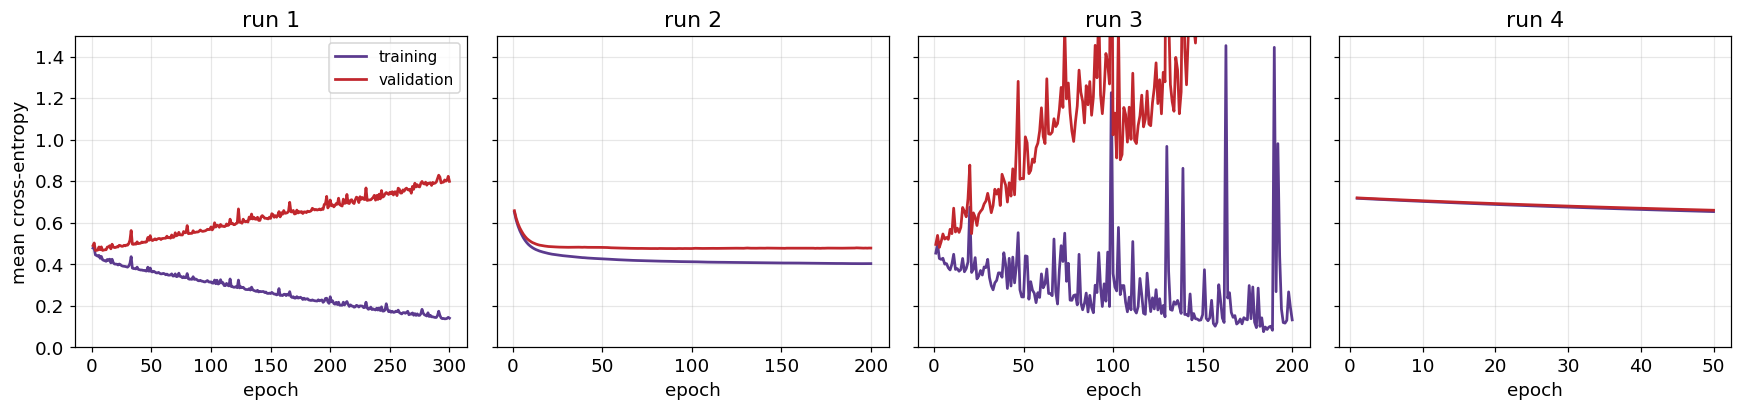

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
for ax, (name, (mod, h)) in zip(axes, results.items()):
    ax.plot(np.arange(1, len(h) + 1), h[:, 0], color="#5b3a8e", lw=1.8, label="training")
    ax.plot(np.arange(1, len(h) + 1), h[:, 1], color="#c1272d", lw=1.8, label="validation")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mean cross-entropy"); axes[0].set_ylim(0, 1.5); axes[0].legend(fontsize=10)
plt.tight_layout(); plt.show()

Diagnose each run from its curves and its settings. Use exactly one of `"underfitting"`,
`"overfitting"`, `"unstable"`, `"sound"` for each, and give the cause in a few words.

> The check confirms the labels. The causes are graded in the submitted notebook, and the reasoning is
> what a defense quiz asks for.

In [20]:
# --- TODO: one label and one cause per run ---
import hashlib

diagnosis = {
    "run 1": ("overfitting", "Large network memorizes training data and noise."),      # (label, cause)
    "run 2": ("sound", "Weight decay regularizes the network and limits overfitting."),
    "run 3": ("unstable", "Learning rate is too high, causing large weight updates."),
    "run 4": ("underfitting", "Learning rate is too low to learn effectively.")
}




labels = {k: v[0] for k, v in diagnosis.items()}
assert set(labels.values()) <= {"underfitting", "overfitting", "unstable", "sound"} and all(labels.values()), \
    "Use exactly one of the four labels for each run."
assert all(len(v[1]) >= 10 for v in diagnosis.values()), "Give a cause for each run."
key = {"run 1": "50d701", "run 2": "0b8263", "run 3": "a6389c", "run 4": "484285"}   # hashes, so the answers are not printed here
assert all(hashlib.md5(labels[k].encode()).hexdigest()[:6] == key[k] for k in key), "At least one label does not match its curves."
print("Diagnoses recorded.")

Diagnoses recorded.


The remedies follow from the diagnoses:

| Run | Behaviour | Remedy |
|---|---|---|
| 1 | overfitting | weight decay; fewer hidden units; early stopping (section 6) |
| 2 | sound | — |
| 3 | unstable | a smaller learning rate |
| 4 | underfitting | a larger learning rate, or more epochs |

> Run 4 underfits because of the optimisation, not the model: 32 hidden units are enough, but 50
> epochs of steps of size 0.001 do not reach a good minimum. Underfitting can also come from a model
> with too little capacity, such as the single hidden unit of Meeting 17, section 6. The curves look
> the same; the settings tell the two apart.

---
## 6 — Early stopping, and the comparison with logistic regression

Run 1's network was best after only a few epochs. **Early stopping** keeps that network: after every
epoch, if the validation loss is the lowest so far, save a copy of the weights; stop when the
validation loss has not improved for `patience` epochs; restore the saved copy.

> `model.state_dict()` returns the weights as a dictionary of tensors, and
> `model.load_state_dict(d)` puts them back. `copy.deepcopy` is needed when saving, because the tensors
> in the dictionary are the live weights and would otherwise keep changing.

Complete `fit_early_stopping`. Then the cell compares the validation AUC of the early-stopped 256-unit
network with that of run 1 trained for all 300 epochs, and with logistic regression.

In [21]:
def fit_early_stopping(m, lr, max_epochs, patience, weight_decay=0.0, seed=0):
    torch.manual_seed(seed)
    model, batches = MLP(m), train_batches()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_loss, best_state, best_epoch, history = np.inf, None, 0, []
    for epoch in range(1, max_epochs + 1):
        run_epoch(model, optimizer, batches)
        history.append(losses(model))
        # --- TODO: keep a copy of the weights when the validation loss is the lowest so far; ---
        # ---       stop when it has not improved for `patience` epochs                        ---

        # check if validation losss is lowest so far
            # if so update best_loss, best_state, best_epoch
        if history[-1][1] < best_loss:
            best_loss = history[-1][1]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        # Stop if validation loss has not improved for patience epochs
        if epoch - best_epoch >= patience:
            break

        # check if we obsevered patience # of epochs without improving
        # If so exit the loop
           #if epoch - best_epoch > patience:
              #break

        # hint: history varibale is a list of arrays or tuples
        # every epoch adds this: training loss, validation loss


        #print(epoch, history[-1], best_epoch)

        pass



    # --- TODO: restore the best weights ---
    model.load_state_dict(best_state)


    return model, np.array(history), best_epoch




def val_auc(model):
    model.eval()
    with torch.no_grad():
        return roc_auc_score(y_va, model(x_va).numpy())

es_model, es_history, es_epoch = fit_early_stopping(m=256, lr=0.1, max_epochs=300, patience=20)
logreg = LogisticRegression().fit(prep.transform(X_tr), y_tr)
assert 1 <= es_epoch < len(es_history) <= es_epoch + 20, "Training should stop `patience` epochs after the best epoch."
assert np.isclose(losses(es_model)[1], es_history[:, 1].min(), atol=1e-6), "The restored model should have the lowest validation loss."
print(f"early stopping: best epoch {es_epoch}, stopped after {len(es_history)} epochs")
print(f"validation AUC   256 units, early-stopped {val_auc(es_model):.3f}   256 units, 300 epochs (run 1) {val_auc(results['run 1'][0]):.3f}   "
      f"logistic regression {roc_auc_score(y_va, logreg.predict_proba(prep.transform(X_va))[:, 1]):.3f}")

early stopping: best epoch 3, stopped after 23 epochs
validation AUC   256 units, early-stopped 0.837   256 units, 300 epochs (run 1) 0.754   logistic regression 0.823


Early stopping recovers the network that run 1 passed through on its way to overfitting: its
validation AUC is far above that of the same network trained for 300 epochs, and close to logistic
regression's.

> The stopping epoch was chosen on the validation set, so the early-stopped network's validation AUC is
> optimistic (Meeting 12). The test set has not been used for any decision.

The cell below evaluates the two final candidates on the test set, once.

In [22]:
# Done for you: the test set, once.
es_model.eval()
with torch.no_grad():
    auc_net = roc_auc_score(y_test, es_model(x_test).numpy())
auc_lr = roc_auc_score(y_test, logreg.predict_proba(prep.transform(X_test))[:, 1])
print(f"test AUC   early-stopped network {auc_net:.3f}   logistic regression {auc_lr:.3f}   ({len(y_test)} women)")

test AUC   early-stopped network 0.818   logistic regression 0.829   (154 women)


On 154 test women the two models are within a few hundredths of each other, a difference well within
the uncertainty of an AUC on so few patients (Meeting 20 quantifies it). The conclusion of Meeting 17,
section 8 stands: on eight routine measurements, the network's extra capacity buys nothing that
logistic regression does not already provide.

What carries over to the capstone and Meetings 21 to 24 is the procedure: a module, a loop, loss curves
read after every run, and a stopping rule decided on validation data.

---
## 7 — Submitting your work

**Due at 11:59 PM EST on Monday, November 16.** changed to NOV 18th.


1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_meeting18.ipynb` and move it into the `checkins/` folder
   of your clone.
4. Commit in GitHub Desktop, push, and open a pull request.
